In [1]:
import regex as re
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

from scipy import stats

from matplotlib import pyplot as plt
import mpl_toolkits.axisartist.axislines as axislines
import matplotlib.transforms as mtransforms
import matplotlib.lines

from statsmodels.formula.api import ols, logit
from stargazer.stargazer import Stargazer

C:\Users\isen1\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# style helpers 

def clean_single(v):
    m = re.search(r'\[T\.(.*)\]', v)
    val = m.group(1) if m else v
    # note: "C(Var, Treatment(reference=...))..." never has a ")" right after
    # the var name (Treatment(...) follows), so only match up to the comma
    grp_m = re.search(r'C\((\w+)', v)
    grp = grp_m.group(1).replace('_', ' ') if grp_m else ''
    return f'{grp}: {val}' if grp else val

def clean_name(v):
    # interaction terms come through as "term1:term2" (patsy notation);
    # clean each side separately and join with a visible interaction marker
    return ' × '.join(clean_single(part) for part in v.split(':'))

def strip_group_prefix(lbl):
    # drop the redundant "GroupName: " prefix clean_name adds -- the
    # group is already shown via the row's Y_GROUPS header, so the axis
    # itself only needs the variant name(s)
    return ' × '.join(part.split(': ', 1)[-1] for part in lbl.split(' × '))

def pretty_label(name):
    return name.replace('_', ' ').title()

In [3]:
# ideology helpers

def reoder_ideology_order(current_labels):
    final_labels = [current_labels[0]]

    conservative_labels = []
    liberal_labels = []
    moderate_labels = []

    for label in current_labels:
        if 'conserv' in label.lower():
            conservative_labels.append(label)
        if 'moderate' in label.lower():
            moderate_labels.append(label)
        if 'lib' in label.lower():
            liberal_labels.append(label)
        
    final_labels = final_labels + sorted(liberal_labels) +\
    sorted(moderate_labels) + [conservative_labels[-1]] + conservative_labels[:2]
    return final_labels

def ideology_color(raw_label):
    text = raw_label.lower()
    if 'conserv' in text:
        return IDEOLOGY_COLORS['conservative']
    if 'lib' in text:
        return IDEOLOGY_COLORS['liberal']
    if 'moderate' in text:
        return IDEOLOGY_COLORS['moderate']
    return IDEOLOGY_COLORS['overall']

In [4]:
agg_results_df = pd.read_csv('results/pre_election/evaluated_results_subgroup_nonadjusted.csv')

In [5]:
agg_results_df = agg_results_df.rename(columns={
    'nonadjusted_weighted_avg': 'nonadjusted_weighted_tvd',
    'adjusted_weighted_avg': 'adjusted_weighted_tvd',
})

In [6]:
plot_df = agg_results_df.copy()
plot_df['Survey Question'] = plot_df.questionnaire_item_id.replace({1: 'Version 1', 2: 'Version 2'})
plot_df['response_type'] = plot_df.response_type.replace({'jsonResponse': 'JSON structured output', 'openResponse': 'open-ended response'})
plot_df['parsing_method'] = plot_df.parsing_method.replace({'jsonParsing': 'JSON parsing', 'regex': 'regex parsing', 'LLMjudge': 'LLM-as-a-judge'})
plot_df['Persona Information'] = plot_df.persona_format.apply(lambda x:'demographic only' if 'demogr' in x else 'demographics & attitudes')
plot_df['Persona Format'] = plot_df.persona_format.apply(lambda x:'direct' if 'Person' in x else 'interview')

plot_df = plot_df.drop(columns=['questionnaire_item_id', 'persona_format', 'sample'])
plot_df = plot_df.rename(columns={
    'response_type': 'Output Generation',
    'model_id': 'LLM model ID',
    'parsing_method': 'Output Parsing',
})

In [7]:
indep_vars = ['Output Generation', 'LLM model ID', 'Output Parsing', 'Survey Question', 'Persona Information',
       'Persona Format']

In [8]:
plot_df = plot_df.rename(columns={i : '_'.join(i.split()) for i in indep_vars})
indep_vars = ['_'.join(i.split()) for i in indep_vars]
plot_df[indep_vars]

,Output_Generation,LLM_model_ID,Output_Parsing,Survey_Question,Persona_Information,Persona_Format
0,JSON structured output,Llama-3.1-8B-Instruct,JSON parsing,Version 1,demographic only,direct
1,JSON structured output,Llama-3.3-70B-Instruct,JSON parsing,Version 1,demographic only,direct
2,JSON structured output,Olmo-3-7B-Instruct,JSON parsing,Version 1,demographic only,direct
3,JSON structured output,Olmo-3.1-32B-Instruct,JSON parsing,Version 1,demographic only,direct
4,JSON structured output,Qwen3-VL-30B-A3B-Instruct,JSON parsing,Version 1,demographic only,direct
...,...,...,...,...,...,...
139,open-ended response,Olmo-3.1-32B-Instruct,regex parsing,Version 2,demographics & attitudes,interview
140,open-ended response,Qwen3-VL-30B-A3B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,interview
141,open-ended response,Qwen3-VL-30B-A3B-Instruct,regex parsing,Version 2,demographics & attitudes,interview
142,open-ended response,Qwen3-VL-8B-Instruct,LLM-as-a-judge,Version 2,demographics & attitudes,interview


In [9]:
for var in indep_vars:
    print(var)
    print(plot_df[var].unique())

Output_Generation
['JSON structured output' 'open-ended response']
LLM_model_ID
['Llama-3.1-8B-Instruct' 'Llama-3.3-70B-Instruct' 'Olmo-3-7B-Instruct'
 'Olmo-3.1-32B-Instruct' 'Qwen3-VL-30B-A3B-Instruct'
 'Qwen3-VL-8B-Instruct']
Output_Parsing
['JSON parsing' 'LLM-as-a-judge' 'regex parsing']
Survey_Question
['Version 1' 'Version 2']
Persona_Information
['demographic only' 'demographics & attitudes']
Persona_Format
['direct' 'interview']


In [10]:
og_dict = {'JSON structured output': 'JSON',
           'open-ended response' : 'free-text'}
model_dict = {'Llama-3.1-8B-Instruct': 'Llama-8B',
              'Llama-3.3-70B-Instruct': 'Llama-70B',
              'Olmo-3-7B-Instruct': 'Olmo-7B',
              'Olmo-3.1-32B-Instruct': 'Olmo-32B',
              'Qwen3-VL-30B-A3B-Instruct': 'Qwen-30B',
              'Qwen3-VL-8B-Instruct': 'Qwen-8B'
             }
op_dict = {'JSON parsing': 'JSON_parsing',
           'LLM-as-a-judge': 'LLM judge',
           'regex parsing': 'regex'}

sq_dict = {'Version 1' : 'v1',
           'Version 2' : 'v2'}

pi_dict = {'demographic only': 'demo',
      'demographics & attitudes' : 'demo+att'}

pf_dict = {'direct' : 'direct',
           'interview' : 'interview'}

In [11]:
### rename everything

og = []
models = []
op = []
sq = []
pi = []
pf = []

for _, row in plot_df.iterrows():
    og.append(og_dict[row['Output_Generation']])
    models.append(model_dict[row['LLM_model_ID']])
    op.append(op_dict[row['Output_Parsing']])
    sq.append(sq_dict[row['Survey_Question']])
    pi.append(pi_dict[row['Persona_Information']])
    pf.append(pf_dict[row['Persona_Format']])
    
plot_df['Output_Generation'] = og
plot_df['LLM_model_ID'] = models
plot_df['Output_Parsing'] = op
plot_df['Survey_Question'] = sq
plot_df['Persona_Information'] = pi
plot_df['Persona_Format'] = pf

In [12]:
### combine persona_format and persona_info into persona construction
plot_df['Persona'] = plot_df['Persona_Information'] + ' (' + plot_df['Persona_Format']  + ')'

In [13]:
plot_df = plot_df.rename(columns = {'Output_Generation': 'Inference',
                                    'LLM_model_ID': 'LLM',
                                    'Output_Parsing': 'Behavior_Proc',
                                    'Survey_Question': 'Task',
                                    })
indep_vars = ['Inference',
'LLM',
    'Behavior_Proc',
    'Task',
    'Persona'
    ]

In [14]:
# Response Generation (Inference) and Response Processing (Behavior_Proc) are
# structurally confounded: JSON parsing only ever occurs with JSON-structured
# output, and regex/LLM-judge parsing only ever occur with free-text output.
# Modeling them as two separate main effects makes the design matrix
# rank-deficient (the "covariance of constraints does not have full rank"
# warning) and the individual coefficients are not uniquely identified. Merge
# them into a single factor, the same way Persona_Information + Persona_Format
# were merged into Persona above.
plot_df['Response_Handling'] = plot_df['Inference'] + ' + ' + plot_df['Behavior_Proc']
indep_vars = ['Response_Handling', 'LLM', 'Task', 'Persona']

In [15]:
plot_df = plot_df.rename(columns = {'f1_Non-voter' : 'f1_Non_voter'})

In [16]:
# The evaluation results store "adjustment" (whether survey/demographic
# weights were used when computing a metric) as parallel columns rather than
# as its own decision choice: f1, tvd, and the gender/ideology subgroup
# metrics are all split into adjusted_<x>/nonadjusted_<x> column pairs.
# Melt every such pair into a single metric column plus a new 'Adjustment'
# decision-choice column.
adjusted_cols = [c for c in plot_df.columns if c.startswith('adjusted_')]
paired_cols = {}
for adj_col in adjusted_cols:
    base = adj_col[len('adjusted_'):]
    nonadj_col = f'nonadjusted_{base}'
    if nonadj_col in plot_df.columns:
        paired_cols[base] = (adj_col, nonadj_col)

paired_flat = {c for pair in paired_cols.values() for c in pair}
id_cols = [c for c in plot_df.columns if c not in paired_flat]

adjusted_df = plot_df[id_cols + [adj for adj, _ in paired_cols.values()]].rename(
    columns={adj: base for base, (adj, _) in paired_cols.items()}).copy()
adjusted_df['Adjustment'] = 'adjusted'

nonadjusted_df = plot_df[id_cols + [nonadj for _, nonadj in paired_cols.values()]].rename(
    columns={nonadj: base for base, (_, nonadj) in paired_cols.items()}).copy()
nonadjusted_df['Adjustment'] = 'non-adjusted'

plot_df = pd.concat([adjusted_df, nonadjusted_df], ignore_index=True)
indep_vars = indep_vars + ['Adjustment']
plot_df

,Inference,LLM,Behavior_Proc,simulated_responses,valid_responses,accuracy,weighted_accuracy,macro_avg_f1,f1_Trump,f1_Harris,...,weighted_tvd_ideology_extremely liberal,weighted_f1_ideology_liberal,weighted_tvd_ideology_liberal,weighted_f1_ideology_moderate,weighted_tvd_ideology_moderate,weighted_f1_ideology_slightly conservative,weighted_tvd_ideology_slightly conservative,weighted_f1_ideology_slightly liberal,weighted_tvd_ideology_slightly liberal,Adjustment
0,JSON,Llama-8B,JSON_parsing,25355,25355,0.510392,0.525109,0.359894,0.593407,0.473064,...,0.460800,0.557685,0.493601,0.405129,0.258451,0.546364,0.123127,0.501261,0.480081,adjusted
1,JSON,Llama-70B,JSON_parsing,25355,25355,0.535831,0.538787,0.378578,0.591929,0.542434,...,0.294532,0.653596,0.373691,0.420454,0.211938,0.533803,0.200065,0.563793,0.390708,adjusted
2,JSON,Olmo-7B,JSON_parsing,25355,25355,0.440032,0.439604,0.268980,0.577623,0.227955,...,0.738040,0.291902,0.775689,0.239734,0.598726,0.500125,0.265309,0.281890,0.744047,adjusted
3,JSON,Olmo-32B,JSON_parsing,25355,25355,0.515283,0.521447,0.405387,0.567246,0.544390,...,0.276535,0.644230,0.359694,0.453073,0.140405,0.545377,0.138609,0.594110,0.327463,adjusted
4,JSON,Qwen-30B,JSON_parsing,25355,25355,0.537961,0.534316,0.398808,0.570651,0.579105,...,0.223819,0.696377,0.299174,0.436036,0.172277,0.509939,0.284801,0.625385,0.298977,adjusted
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,free-text,Olmo-32B,regex,25355,23737,NaN,NaN,0.597095,0.856814,0.874607,...,0.049123,0.923909,0.033665,0.658706,0.111576,0.678287,0.115698,0.859828,0.039272,non-adjusted
284,free-text,Qwen-30B,LLM judge,25355,25355,0.802011,0.769048,0.581513,0.843241,0.853775,...,0.107018,0.922031,0.052174,0.636496,0.158949,0.654074,0.115116,0.841627,0.100383,non-adjusted
285,free-text,Qwen-30B,regex,25355,25277,NaN,NaN,0.565786,0.843446,0.853912,...,0.107018,0.920753,0.053043,0.630946,0.160700,0.652913,0.115698,0.841627,0.100383,non-adjusted
286,free-text,Qwen-8B,LLM judge,25355,25355,0.781266,0.762095,0.589525,0.807096,0.843348,...,0.063158,0.923844,0.040000,0.613170,0.221401,0.603008,0.265891,0.790379,0.130268,non-adjusted


## descriptive results

- overall performance and best-performing design choice variant
- difference between best and worst design configuration
- is the best configuration the same between both metrics
- rank correlation between tvd and f1 rankings of configs

In [17]:
metrics_for_table = ['weighted_f1', 'weighted_tvd']

In [18]:
mean = {}
std = {}
for metric in metrics_for_table:
    mean[metric] = {}
    std[metric] = {}
    for var in indep_vars:
        mean[metric][var] = dict(plot_df.groupby(var).mean(numeric_only = True)[metric])
        std[metric][var] = dict(plot_df.groupby(var).std(numeric_only = True)[metric])

In [19]:
table = {}
for metric in metrics_for_table:
    df_rows = []
    for var in mean[metric]:
        for var2 in mean[metric][var]:
            num = str(mean[metric][var][var2].round(3)) + ' \u00B1 ' + str(std[metric][var][var2].round(2))
            df_rows.append([var, var2, num])
    
    num = str(plot_df.mean(numeric_only = True)[metric].round(3)) + ' \u00B1 ' \
          + str(plot_df.std(numeric_only = True)[metric].round(2))
    df_rows.append(['Overall', 'Overall', num])
    table[metric] = pd.DataFrame(df_rows)
    table[metric].columns = ['Design Choice', 'Variant', '%s' %(metric)]
    
table_df = table[metrics_for_table[0]]
for metric in metrics_for_table[1:]:
    table_df = table_df.merge(table[metric])

In [20]:
table_df

,Design Choice,Variant,weighted_f1,weighted_tvd
0,Response_Handling,JSON + JSON_parsing,0.615 ± 0.15,0.227 ± 0.1
1,Response_Handling,free-text + LLM judge,0.609 ± 0.15,0.202 ± 0.09
2,Response_Handling,free-text + regex,0.59 ± 0.13,0.209 ± 0.08
3,LLM,Llama-70B,0.626 ± 0.13,0.208 ± 0.06
4,LLM,Llama-8B,0.593 ± 0.12,0.197 ± 0.07
5,LLM,Olmo-32B,0.619 ± 0.17,0.171 ± 0.09
6,LLM,Olmo-7B,0.549 ± 0.15,0.267 ± 0.13
7,LLM,Qwen-30B,0.629 ± 0.14,0.206 ± 0.08
8,LLM,Qwen-8B,0.614 ± 0.13,0.226 ± 0.08
9,Task,v1,0.606 ± 0.14,0.212 ± 0.09


In [21]:
print(table_df.to_latex())

\begin{tabular}{lllll}
\toprule
 & Design Choice & Variant & weighted_f1 & weighted_tvd \\
\midrule
0 & Response_Handling & JSON + JSON_parsing & 0.615 ± 0.15 & 0.227 ± 0.1 \\
1 & Response_Handling & free-text + LLM judge & 0.609 ± 0.15 & 0.202 ± 0.09 \\
2 & Response_Handling & free-text + regex & 0.59 ± 0.13 & 0.209 ± 0.08 \\
3 & LLM & Llama-70B & 0.626 ± 0.13 & 0.208 ± 0.06 \\
4 & LLM & Llama-8B & 0.593 ± 0.12 & 0.197 ± 0.07 \\
5 & LLM & Olmo-32B & 0.619 ± 0.17 & 0.171 ± 0.09 \\
6 & LLM & Olmo-7B & 0.549 ± 0.15 & 0.267 ± 0.13 \\
7 & LLM & Qwen-30B & 0.629 ± 0.14 & 0.206 ± 0.08 \\
8 & LLM & Qwen-8B & 0.614 ± 0.13 & 0.226 ± 0.08 \\
9 & Task & v1 & 0.606 ± 0.14 & 0.212 ± 0.09 \\
10 & Task & v2 & 0.604 ± 0.14 & 0.213 ± 0.09 \\
11 & Persona & demo (direct) & 0.474 ± 0.04 & 0.268 ± 0.06 \\
12 & Persona & demo (interview) & 0.465 ± 0.05 & 0.303 ± 0.07 \\
13 & Persona & demo+att (direct) & 0.75 ± 0.04 & 0.126 ± 0.03 \\
14 & Persona & demo+att (interview) & 0.731 ± 0.05 & 0.153 ± 0.04 \\
15 &

In [22]:
# best and worst configuration
best = {}
worst = {}
for metric in metrics_for_table:
    if metric == 'weighted_tvd':
        best[metric+'_config_id'] = plot_df.sort_values(metric).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric)[metric].iloc[-1]
    else:
        best[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[0]
        worst[metric+'_config_id'] = plot_df.sort_values(metric, ascending=False).index[-1]
        best[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[0]
        worst[metric+'_config'] = plot_df.sort_values(metric, ascending=False)[indep_vars].iloc[-1]
        best[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[0]
        worst[metric+'_val'] = plot_df.sort_values(metric, ascending=False)[metric].iloc[-1]

In [23]:
best

{'weighted_f1_config_id': 237,
 'weighted_f1_config': Response_Handling     JSON + JSON_parsing
 LLM                              Olmo-32B
 Task                                   v2
 Persona              demo+att (interview)
 Adjustment                   non-adjusted
 Name: 237, dtype: object,
 'weighted_f1_val': 0.8278609685627815,
 'weighted_tvd_config_id': 282,
 'weighted_tvd_config': Response_Handling    free-text + LLM judge
 LLM                               Olmo-32B
 Task                                    v2
 Persona               demo+att (interview)
 Adjustment                    non-adjusted
 Name: 282, dtype: object,
 'weighted_tvd_val': 0.0600178451783241}

In [24]:
worst

{'weighted_f1_config_id': 256,
 'weighted_f1_config': Response_Handling    free-text + LLM judge
 LLM                                Olmo-7B
 Task                                    v2
 Persona                   demo (interview)
 Adjustment                    non-adjusted
 Name: 256, dtype: object,
 'weighted_f1_val': 0.337584299478252,
 'weighted_tvd_config_id': 146,
 'weighted_tvd_config': Response_Handling    JSON + JSON_parsing
 LLM                              Olmo-7B
 Task                                  v1
 Persona                    demo (direct)
 Adjustment                  non-adjusted
 Name: 146, dtype: object,
 'weighted_tvd_val': 0.506028170073062}

In [25]:
stats.spearmanr(plot_df[metrics_for_table[0]], plot_df[metrics_for_table[1]])

SignificanceResult(statistic=-0.8615283990210145, pvalue=3.4956661667806685e-86)

In [26]:
plot_df.loc[[237, 282, 256, 146]][metrics_for_table]

,weighted_f1,weighted_tvd
237,0.827861,0.070314
282,0.819538,0.060018
256,0.337584,0.460983
146,0.341858,0.506028


In [27]:
# create table for best and worst

df1 = pd.DataFrame.from_dict(best).T
df2 = pd.DataFrame.from_dict(worst).T
print(pd.concat([df1, df2]).to_latex())

\begin{tabular}{llllll}
\toprule
 & Response_Handling & LLM & Task & Persona & Adjustment \\
\midrule
weighted_f1_config_id & 237 & 237 & 237 & 237 & 237 \\
weighted_f1_config & JSON + JSON_parsing & Olmo-32B & v2 & demo+att (interview) & non-adjusted \\
weighted_f1_val & 0.827861 & 0.827861 & 0.827861 & 0.827861 & 0.827861 \\
weighted_tvd_config_id & 282 & 282 & 282 & 282 & 282 \\
weighted_tvd_config & free-text + LLM judge & Olmo-32B & v2 & demo+att (interview) & non-adjusted \\
weighted_tvd_val & 0.060018 & 0.060018 & 0.060018 & 0.060018 & 0.060018 \\
weighted_f1_config_id & 256 & 256 & 256 & 256 & 256 \\
weighted_f1_config & free-text + LLM judge & Olmo-7B & v2 & demo (interview) & non-adjusted \\
weighted_f1_val & 0.337584 & 0.337584 & 0.337584 & 0.337584 & 0.337584 \\
weighted_tvd_config_id & 146 & 146 & 146 & 146 & 146 \\
weighted_tvd_config & JSON + JSON_parsing & Olmo-7B & v1 & demo (direct) & non-adjusted \\
weighted_tvd_val & 0.506028 & 0.506028 & 0.506028 & 0.506028 & 0.506

## regressions for determining impact of design choices, with LLM interactions

Same regressions and lollipop plots as `regression.ipynb`, but the formula additionally includes
the interaction of `LLM` with each of the other three design choices (`Response_Handling`, `Task`,
`Persona`), so we can see whether the effect of a design choice differs by which LLM generated the responses.

In [28]:
metrics_for_table

['weighted_f1', 'weighted_tvd']

In [29]:
main_metric = metrics_for_table[0]

In [30]:
# get the reference categories: for each design choice, the variant that
# achieves the highest mean on the main metric, flip for TVD

if 'tvd' in main_metric:
    refs = {
        var: plot_df.groupby(var)[main_metric].mean().idxmin()
        for var in indep_vars
    }
else:
    refs = {
        var: plot_df.groupby(var)[main_metric].mean().idxmax()
        for var in indep_vars
    }
refs

{'Response_Handling': 'JSON + JSON_parsing',
 'LLM': 'Qwen-30B',
 'Task': 'v1',
 'Persona': 'demo+att (direct)',
 'Adjustment': 'non-adjusted'}

In [31]:
formula = ''
for var in indep_vars:
    formula = formula + 'C(' + var + ', Treatment(reference=\'' + refs[var] + '\'))+'

formula = formula[:-1]

# add interaction terms between LLM and every other design choice, so the
# effect of each design choice can vary by which LLM generated the responses
interaction_var = 'LLM'
interaction_terms = '+'.join(
    'C(%s, Treatment(reference=\'%s\')):C(%s, Treatment(reference=\'%s\'))'
    % (interaction_var, refs[interaction_var], var, refs[var])
    for var in indep_vars if var != interaction_var
)
formula = formula + '+' + interaction_terms

In [32]:
formula

"C(Response_Handling, Treatment(reference='JSON + JSON_parsing'))+C(LLM, Treatment(reference='Qwen-30B'))+C(Task, Treatment(reference='v1'))+C(Persona, Treatment(reference='demo+att (direct)'))+C(Adjustment, Treatment(reference='non-adjusted'))+C(LLM, Treatment(reference='Qwen-30B')):C(Response_Handling, Treatment(reference='JSON + JSON_parsing'))+C(LLM, Treatment(reference='Qwen-30B')):C(Task, Treatment(reference='v1'))+C(LLM, Treatment(reference='Qwen-30B')):C(Persona, Treatment(reference='demo+att (direct)'))+C(LLM, Treatment(reference='Qwen-30B')):C(Adjustment, Treatment(reference='non-adjusted'))"

In [33]:
### create aregression plot broken down by gender subgroup
### works for any metric of interest (F1 or TVD), not just F1 -- see subgroup_metric below

In [34]:
# Which per-subgroup metric family the gender/ideology figures below break
# down by -- derived from main_metric so switching main_metric to 'weighted_tvd'
# automatically switches every subgroup figure to use the
# weighted_tvd_gender_*/weighted_tvd_ideology_* columns instead of
# weighted_f1_gender_*/weighted_f1_ideology_*,
# with no other code changes needed.

subgroup_metric = main_metric

# label the gender (sex) categories as groups ("male" -> "Men"),
# fall back to the raw category name
CATEGORY_LABEL_FIXES = {'male': 'men', 'female': 'women'}

In [35]:
# discover the gender subgroup columns for the chosen metric rather than hardcoding their names
gender_cols = [c for c in plot_df.columns if c.startswith(f'{subgroup_metric}_gender_')]
gender_categories = {c: c.replace(f'{subgroup_metric}_gender_', '') for c in gender_cols}
gender_rename = {
    c: f'{subgroup_metric.upper()}_' + CATEGORY_LABEL_FIXES.get(cat, cat).replace(' ', '_')
    for c, cat in gender_categories.items()
}

plot_df_gender = plot_df.rename(columns=gender_rename)

dep_vars_gender = [main_metric] + list(gender_rename.values())

regs_gender = []
for dep_var in dep_vars_gender:
    regs_gender.append(ols(f"{dep_var} ~ {formula}",
          data = plot_df_gender).fit(cov_type = 'HC3'))

In [36]:
model_labels_gender_raw = ['Overall'] + [
    f'{CATEGORY_LABEL_FIXES.get(cat, cat).title()}'
    for cat in gender_categories.values()
]

all_coefs_gender = []
for reg, label in zip(regs_gender, model_labels_gender_raw):
    ci = reg.conf_int()
    df_c = pd.DataFrame({
        'coef': reg.params,
        'ci_low': ci[0],
        'ci_high': ci[1],
        'pvalue': reg.pvalues,
        'model': label
    })
    df_c = df_c[df_c.index != 'Intercept']
    all_coefs_gender.append(df_c)

coef_df_gender = pd.concat(all_coefs_gender).reset_index().rename(columns={'index': 'variable'})
coef_df_gender['label'] = coef_df_gender['variable'].apply(clean_name)

In [37]:
gender_f1_dict = {
    raw: f'{raw} (mean = {plot_df_gender[dep_var].mean():.2f})'
    for raw, dep_var in zip(model_labels_gender_raw, dep_vars_gender)
}

coef_df_gender['model'] = [gender_f1_dict[i] for i in coef_df_gender['model']]
model_labels_gender = [gender_f1_dict[raw] for raw in model_labels_gender_raw]

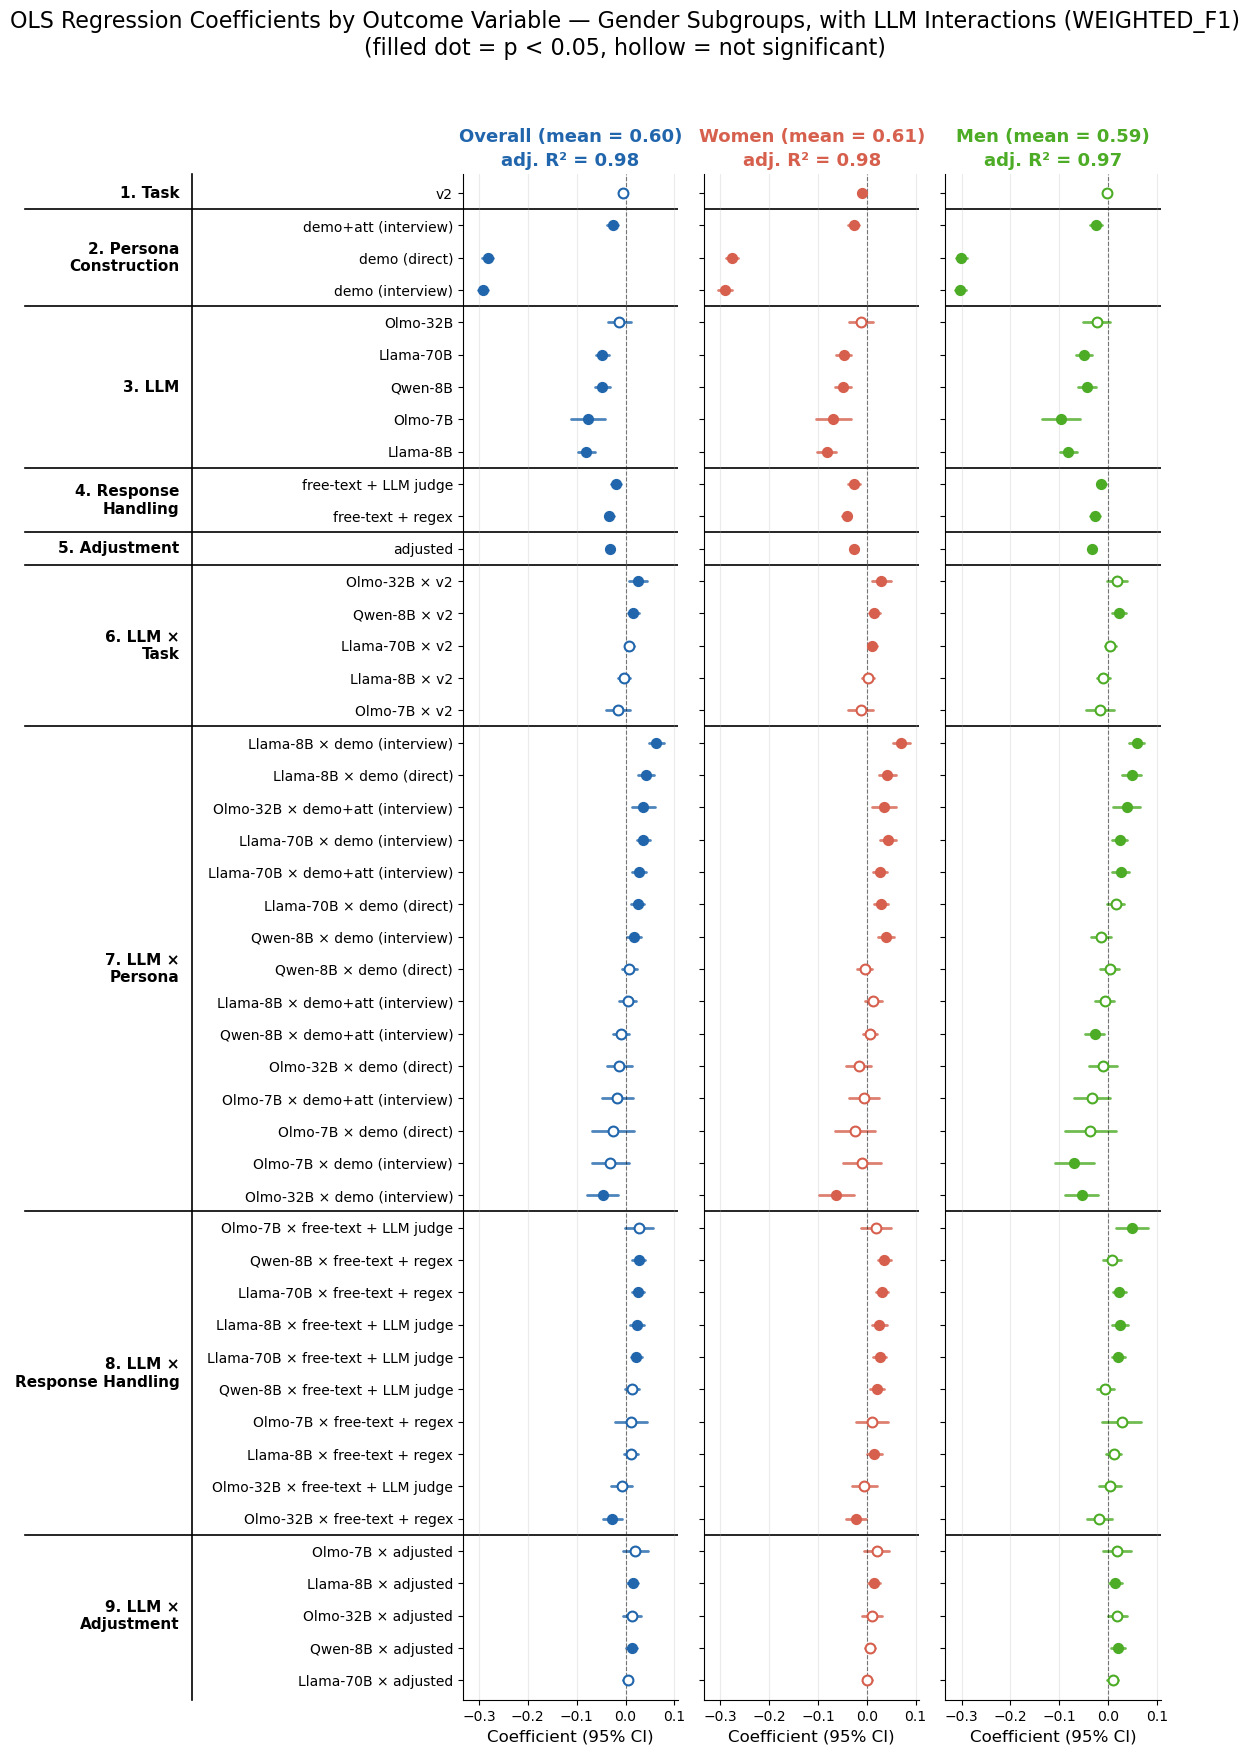

In [38]:
# ---- Grouped y-axis (main effects + LLM interaction terms), broken down by gender subgroup for `subgroup_metric` ----
colors = ['#2166ac', '#d6604d', '#4dac26', '#b35806']

# NB: clean_name() prefixes each term with the design-choice name with
# underscores turned into spaces (e.g. "Response Handling: free-text + regex"),
# so these group keys use spaces to match.
BASE_VARS = ['Task', 'Persona', 'LLM', 'Response Handling', 'Adjustment']
GROUP_HEADERS = {
    'Task': '1. Task',
    'Persona': '2. Persona\nConstruction',
    'LLM': '3. LLM',
    'Response Handling': '4. Response\nHandling',
    'Adjustment': '5. Adjustment',
    'LLM × Task': '6. LLM ×\nTask',
    'LLM × Persona': '7. LLM ×\nPersona',
    'LLM × Response Handling': '8. LLM ×\nResponse Handling',
    'LLM × Adjustment': '9. LLM ×\nAdjustment',
}
GROUP_VAR_ORDER = ['Task', 'Persona', 'LLM', 'Response Handling', 'Adjustment',
                   'LLM × Task', 'LLM × Persona', 'LLM × Response Handling',
                   'LLM × Adjustment']

def base_group_of(lbl):
    for g in BASE_VARS:
        if lbl.startswith(g + ':') or lbl == g:
            return g
    return None

def group_of(lbl):
    # interaction term labels come through clean_name as "term1 × term2"
    if ' × ' in lbl:
        parts = lbl.split(' × ')
        if len(parts) == 2:
            g1, g2 = base_group_of(parts[0]), base_group_of(parts[1])
            other = g2 if g1 == 'LLM' else (g1 if g2 == 'LLM' else None)
            if other is not None:
                return f'LLM × {other}'
        return 'other'
    return base_group_of(lbl) or 'other'

def ranked_items_for_group(group_name, coef_df, overall_label):
    # order items within a group by their coefficient in the Overall model,
    # descending, mirroring how main effects used to be ranked by data mean
    subset = coef_df[coef_df['model'] == overall_label].set_index('label')
    items = [lbl for lbl in subset.index if group_of(lbl) == group_name]
    return list(subset.loc[items, 'coef'].sort_values(ascending=False).index)

Y_GROUPS = [(GROUP_HEADERS[g], ranked_items_for_group(g, coef_df_gender, model_labels_gender[0]))
            for g in GROUP_VAR_ORDER]
Y_GROUPS = [(header, items) for header, items in Y_GROUPS if items]

ordered_items = [it for _, its in Y_GROUPS for it in its]
n_vars = len(ordered_items)
y_pos = {it: n_vars - 1 - i for i, it in enumerate(ordered_items)}

fig, axes = plt.subplots(1, len(regs_gender), figsize=(16.5 * len(regs_gender) / 4, max(4.8, n_vars * 0.35 + 0.7)),
                         sharey=True, sharex=True)

for ax, label, color, reg in zip(axes, model_labels_gender, colors, regs_gender):
    subset = coef_df_gender[coef_df_gender['model'] == label].set_index('label')
    for var in ordered_items:
        if var not in subset.index:
            continue
        row = subset.loc[var]
        y = y_pos[var]
        sig = row['pvalue'] < 0.05
        ax.plot([row['ci_low'], row['ci_high']], [y, y],
                color=color, linewidth=2, alpha=0.8, solid_capstyle='round')
        if sig:
            ax.scatter(row['coef'], y, color=color, s=50, zorder=5)
        else:
            ax.scatter(row['coef'], y, facecolors='white', edgecolors=color,
                       linewidths=1.5, s=50, zorder=5)

    ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.set_title(f'{label}\nadj. R² = {reg.rsquared_adj:.2f}', color=color,
                 fontsize=13, fontweight='bold', linespacing=1.4)
    ax.set_xlabel('Coefficient (95% CI)', fontsize=12)
    ax.grid(axis='x', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_yticks([y_pos[it] for it in ordered_items])
axes[0].set_yticklabels([strip_group_prefix(it) for it in ordered_items], fontsize=10)
axes[0].set_ylim(-0.6, n_vars - 0.4)

# reserve a (modest) left gutter for the horizontal group labels
fig.tight_layout(rect=[0.20, 0, 1, 0.96])
fig.canvas.draw()                       # realize tick-label positions

pos = axes[0].get_position()
inv = fig.transFigure.inverted()
rend = fig.canvas.get_renderer()

# left edge of the inner tick labels (figure coords)
inner_left = min(t.get_window_extent(rend).transformed(inv).x0
                 for t in axes[0].get_yticklabels())

divider_x   = inner_left - 0.012        # divider just left of the inner labels
label_right = divider_x - 0.010         # group labels end just left of the divider
sep_left    = divider_x - 0.135         # separators start left of the group labels

trans = mtransforms.blended_transform_factory(fig.transFigure, axes[0].transData)

# (2) horizontal group labels, RIGHT-aligned right next to the inner labels
for header, its in Y_GROUPS:
    yc = np.mean([y_pos[it] for it in its])
    axes[0].text(label_right, yc, header, transform=trans, rotation=0,
                 ha='right', va='center', fontsize=11, fontweight='bold',
                 clip_on=False)
    
boundaries, cum = [], 0
for _, its in Y_GROUPS[:-1]:
    cum += len(its)
    boundaries.append((n_vars - 1 - cum) + 0.5)

# (3) horizontal separators extended across the gutter (through the group labels)
for b in boundaries:
    fig.add_artist(matplotlib.lines.Line2D([sep_left, pos.x0], [b, b],
                   transform=trans, color='black', linewidth=1.2))  # gutter segment
    for ax in axes:
        ax.axhline(b, color='black', linewidth=1.2, zorder=1)       # panel segments

# vertical divider between group labels and inner labels (height = plot height)
fig.add_artist(matplotlib.lines.Line2D([divider_x, divider_x], [pos.y0, pos.y1],
               transform=fig.transFigure, color='black', linewidth=1.2))

fig.suptitle(f'OLS Regression Coefficients by Outcome Variable — Gender Subgroups, with LLM Interactions ({subgroup_metric.upper()})\n'
             '(filled dot = p < 0.05, hollow = not significant)',
             fontsize=16, y=1.02, x = 0.55)

plt.savefig(f'results/pre_election/regression_lollipop_gender_interactions_{subgroup_metric}_v2.pdf', dpi=150, bbox_inches='tight')
plt.show()

### create a similar plot but for political leaning (ideology) subgroups
there are more subgroups than fit in one row of 4, so wrap onto extra rows
also works for any metric of interest (F1 or TVD) via the shared subgroup_metric

In [39]:
ideology_cols = [c for c in plot_df.columns if c.startswith(f'{subgroup_metric}_ideology_')]
plot_df_ideology = plot_df.rename({main : main.replace('extremely', 'extrm') for main in ideology_cols}, axis = 1)
plot_df_ideology = plot_df_ideology.rename({main : main.replace('slightly', 'slight') for main in ideology_cols}, axis = 1)

ideology_cols = [c for c in plot_df_ideology.columns if c.startswith(f'{subgroup_metric}_ideology_')]
plot_df_ideology = plot_df_ideology.rename({main : main.replace('liberal', 'lib') for main in ideology_cols}, axis = 1)
plot_df_ideology = plot_df_ideology.rename({main : main.replace('conservative', 'conserv') for main in ideology_cols}, axis = 1)
ideology_cols = [c for c in plot_df_ideology.columns if c.startswith(f'{subgroup_metric}_ideology_')]

In [40]:
# discover the ideology subgroup columns for the chosen metric rather than hardcoding their names
ideology_categories = {c: c.replace(f'{subgroup_metric}_ideology_', '') for c in ideology_cols}
ideology_rename = {
    c: f'{subgroup_metric.upper()}_' + cat.replace(' ', '_')
    for c, cat in ideology_categories.items()
}

plot_df_ideology = plot_df_ideology.rename(columns=ideology_rename)

dep_vars_ideology = [subgroup_metric] + list(ideology_rename.values())
model_labels_ideology_raw = ['Overall'] + [
    f'{cat.title()}' for cat in ideology_categories.values()
]

In [41]:
model_labels_ideology_raw = reoder_ideology_order(model_labels_ideology_raw)
dep_vars_ideology = reoder_ideology_order(dep_vars_ideology)

In [42]:
regs_ideology = []
for dep_var in dep_vars_ideology:
    regs_ideology.append(ols(f"{dep_var} ~ {formula}",
          data = plot_df_ideology).fit(cov_type = 'HC3'))

In [43]:
all_coefs_ideology = []
for reg, label in zip(regs_ideology, model_labels_ideology_raw):
    ci = reg.conf_int()
    df_c = pd.DataFrame({
        'coef': reg.params,
        'ci_low': ci[0],
        'ci_high': ci[1],
        'pvalue': reg.pvalues,
        'model': label
    })
    df_c = df_c[df_c.index != 'Intercept']
    all_coefs_ideology.append(df_c)

coef_df_ideology = pd.concat(all_coefs_ideology).reset_index().rename(columns={'index': 'variable'})
coef_df_ideology['label'] = coef_df_ideology['variable'].apply(clean_name)

In [44]:
ideology_f1_dict = {
    raw: f'{raw} (mean = {plot_df_ideology[dep_var].mean():.2f})'
    for raw, dep_var in zip(model_labels_ideology_raw, dep_vars_ideology)
}

coef_df_ideology['model'] = [ideology_f1_dict[i] for i in coef_df_ideology['model']]
model_labels_ideology = [ideology_f1_dict[raw] for raw in model_labels_ideology_raw]

In [45]:
def plot_grouped_lollipop(specs, coef_df, Y_GROUPS, ordered_items, y_pos, n_vars, boundaries,
                           suptitle, savepath, ncols_max=4):
    """Grid of lollipop coefficient panels, one per (label, color, reg) in `specs`,
    wrapping onto additional rows so each row has at most `ncols_max` subfigures."""
    n_panels = len(specs)
    ncols = min(n_panels, ncols_max)
    nrows = int(np.ceil(n_panels / ncols_max))

    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(17.5 * ncols / ncols_max, nrows * max(4, n_vars * 0.3 + 1.2)),
                              sharey=True, sharex=True, squeeze=False)

    for idx in range(nrows * ncols):
        r, c = divmod(idx, ncols)
        ax = axes[r][c]
        if idx >= n_panels:
            ax.axis('off')
            continue
        label, color, reg = specs[idx]
        subset = coef_df[coef_df['model'] == label].set_index('label')
        for var in ordered_items:
            if var not in subset.index:
                continue
            row = subset.loc[var]
            y = y_pos[var]
            sig = row['pvalue'] < 0.05
            ax.plot([row['ci_low'], row['ci_high']], [y, y],
                    color=color, linewidth=2, alpha=0.8, solid_capstyle='round')
            if sig:
                ax.scatter(row['coef'], y, color=color, s=50, zorder=5)
            else:
                ax.scatter(row['coef'], y, facecolors='white', edgecolors=color,
                           linewidths=1.5, s=50, zorder=5)

        ax.axvline(0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
        # break the mean annotation onto its own line so long subgroup names
        # (e.g. "F1 Extremely Conservative (mean = 0.23)") don't collide with
        # the neighboring panel's title
        if ' (mean' in label:
            title_name, mean_part = label.split(' (mean', 1)
            mean_part = '(mean' + mean_part
        else:
            title_name, mean_part = label, ''
        title = title_name + (f' {mean_part}' if mean_part else '') \
                + f'\nadj. R² = {reg.rsquared_adj:.2f}'
        ax.set_title(title, color=color, fontsize=11, fontweight='bold', linespacing=1.4)
        ax.set_xlabel('Coefficient (95% CI)', fontsize=12)
        ax.grid(axis='x', alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)

    for r in range(nrows):
        axes[r][0].set_yticks([y_pos[it] for it in ordered_items])
        axes[r][0].set_yticklabels([strip_group_prefix(it) for it in ordered_items], fontsize=11)
        axes[r][0].set_ylim(-0.6, n_vars - 0.4)

    # reserve a (modest) left gutter for the horizontal group labels
    fig.tight_layout(rect=[0.18, 0, 1, 0.96])
    fig.canvas.draw()                       # realize tick-label positions
    inv = fig.transFigure.inverted()
    rend = fig.canvas.get_renderer()

    for r in range(nrows):
        ax0 = axes[r][0]
        pos = ax0.get_position()

        # left edge of the inner tick labels (figure coords)
        inner_left = min(t.get_window_extent(rend).transformed(inv).x0
                         for t in ax0.get_yticklabels())

        divider_x   = inner_left - 0.012        # divider just left of the inner labels
        label_right = divider_x - 0.010         # group labels end just left of the divider
        sep_left    = divider_x - 0.105         # separators start left of the group labels

        trans = mtransforms.blended_transform_factory(fig.transFigure, ax0.transData)

        # horizontal group labels, RIGHT-aligned right next to the inner labels
        for header, its in Y_GROUPS:
            yc = np.mean([y_pos[it] for it in its])
            ax0.text(label_right, yc, header, transform=trans, rotation=0,
                     ha='right', va='center', fontsize=12, fontweight='bold',
                     clip_on=False)

        # horizontal separators extended across the gutter (through the group labels)
        for b in boundaries:
            fig.add_artist(matplotlib.lines.Line2D([sep_left, pos.x0], [b, b],
                           transform=trans, color='black', linewidth=1.2))  # gutter segment
            for c in range(ncols):
                axes[r][c].axhline(b, color='black', linewidth=1.2, zorder=1)  # panel segments

        # vertical divider between group labels and inner labels (height = row's plot height)
        fig.add_artist(matplotlib.lines.Line2D([divider_x, divider_x], [pos.y0, pos.y1],
                       transform=fig.transFigure, color='black', linewidth=1.2))

    fig.suptitle(suptitle, fontsize=16, y=.98, x=0.55)
    plt.savefig(savepath, dpi=150, bbox_inches='tight')
    plt.show()

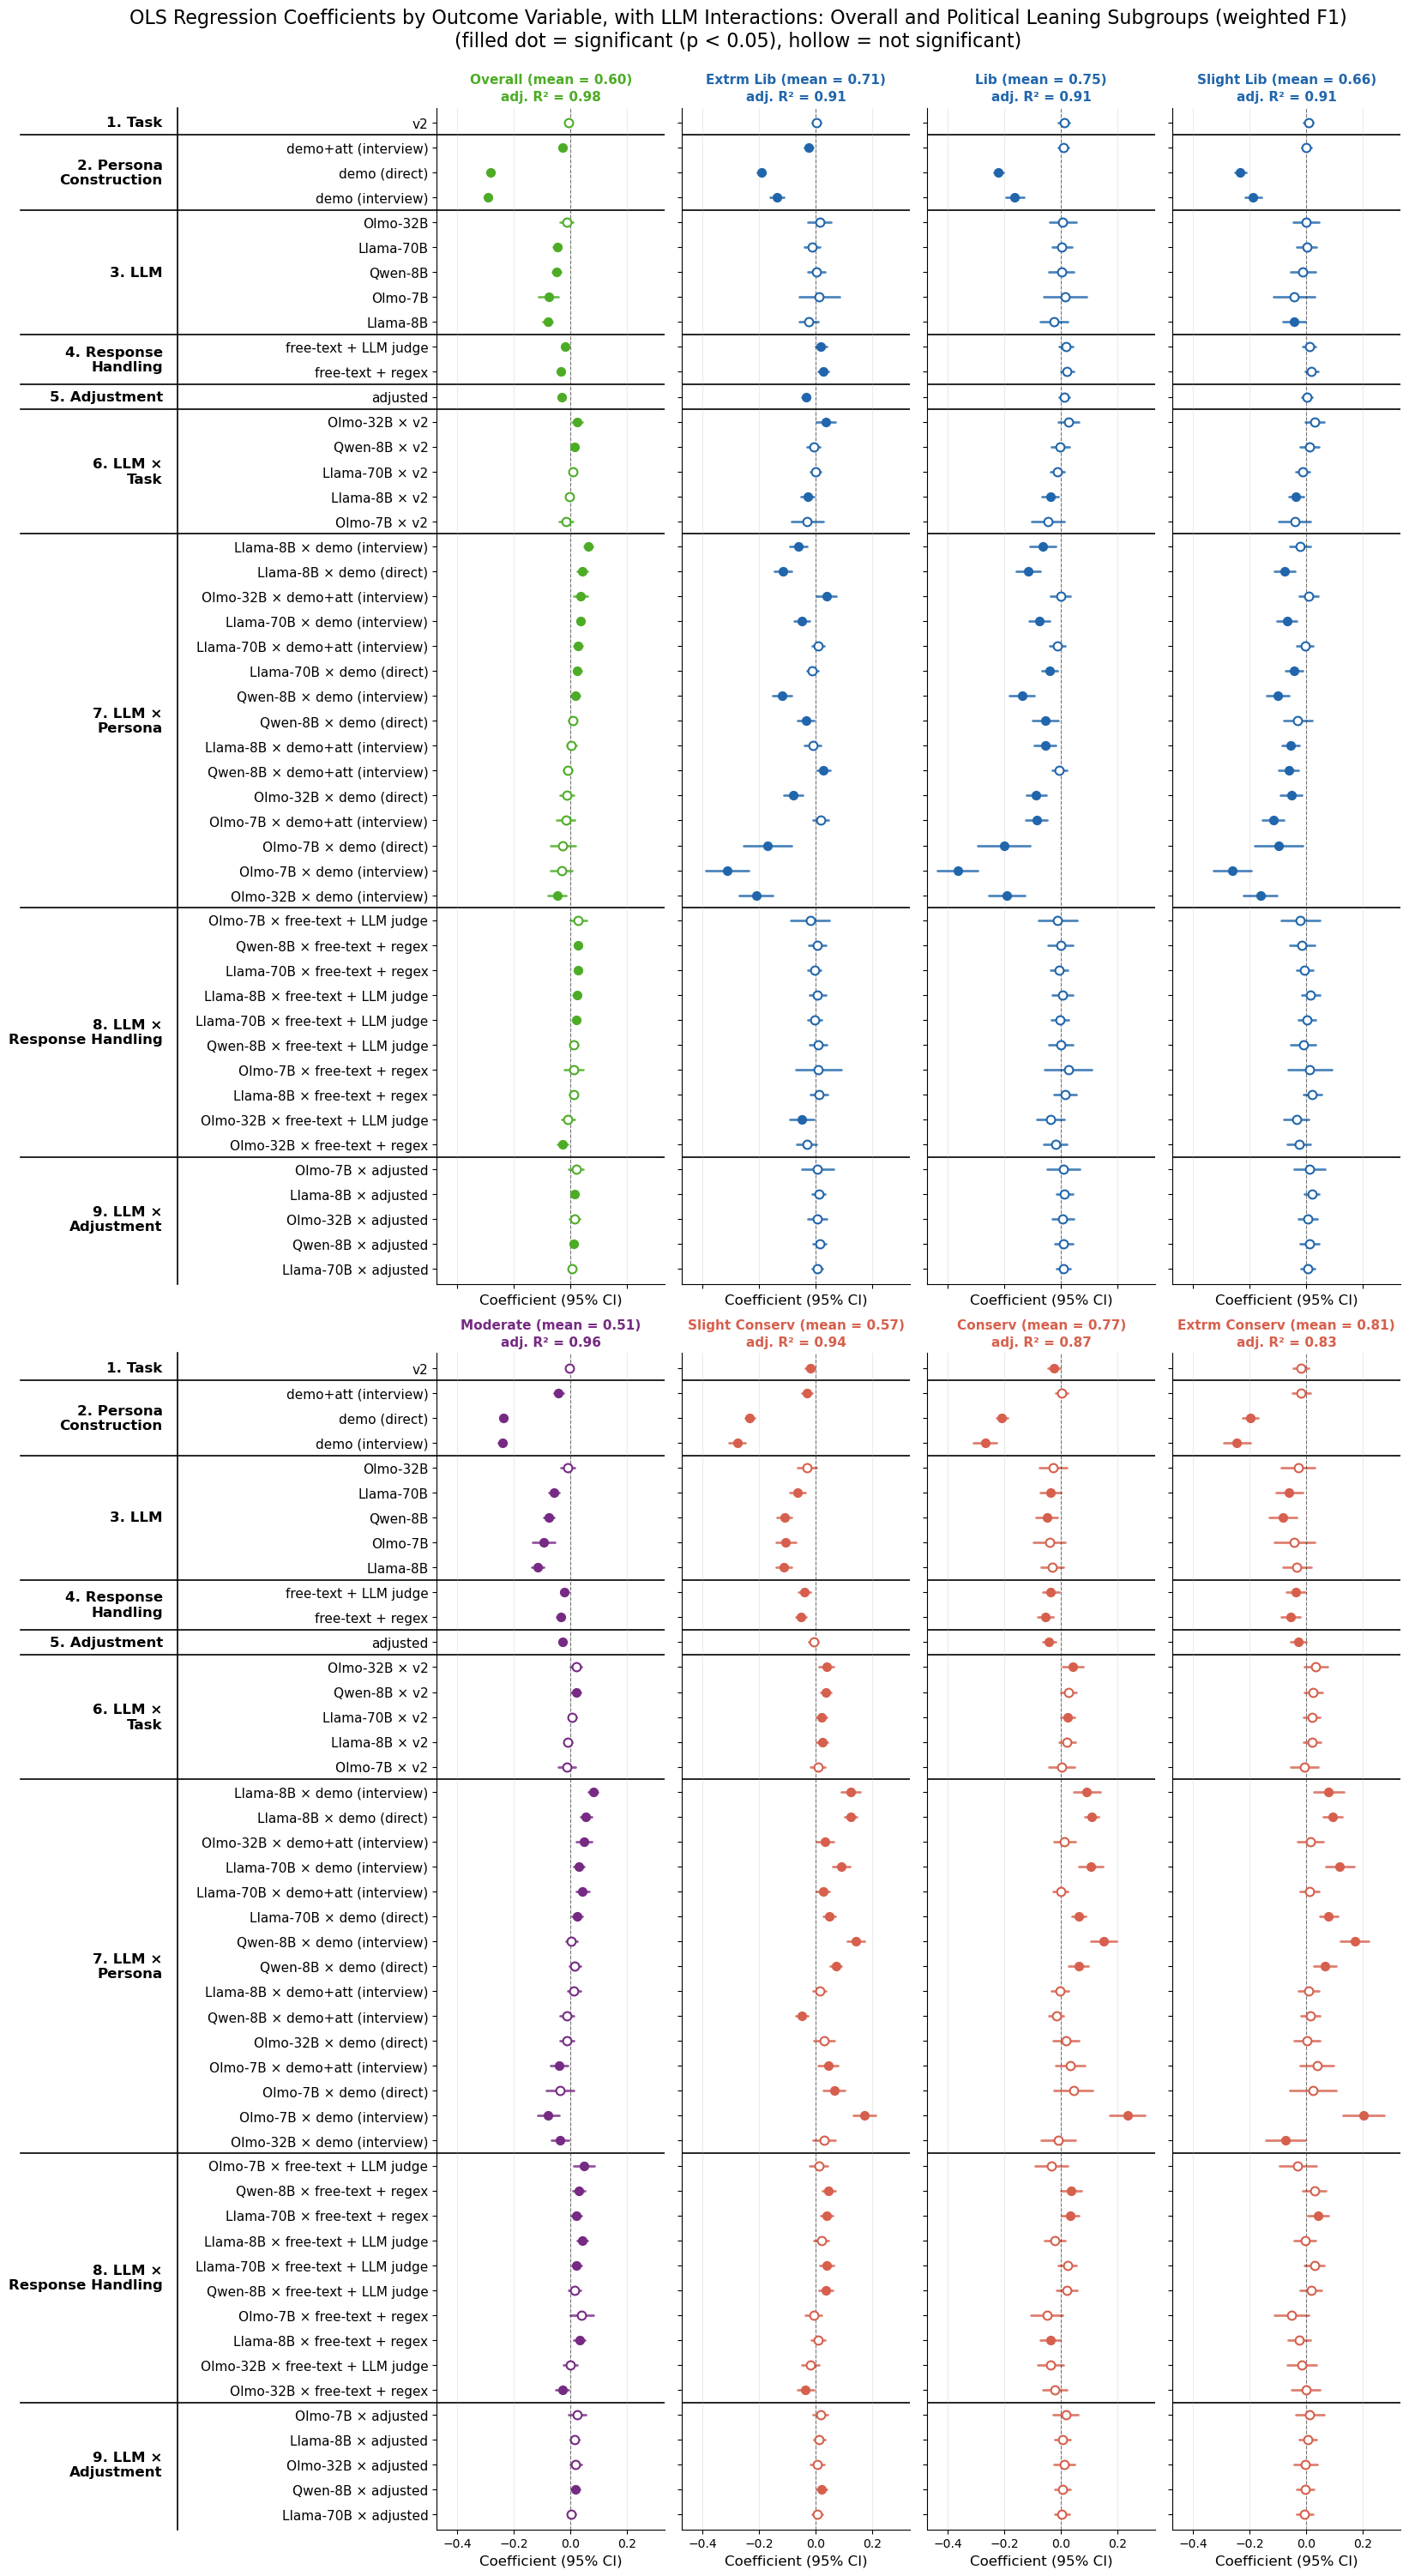

In [46]:
IDEOLOGY_COLORS = {
    'conservative': '#d6604d',  # red — all conservative-leaning subgroups
    'liberal': '#2166ac',       # blue — all liberal-leaning subgroups
    'moderate': '#762a83',      # purple — moderate
    'overall': '#4dac26',       # green — overall metric
}

specs_ideology = list(zip(
    model_labels_ideology,
    [ideology_color(raw) for raw in model_labels_ideology_raw],
    regs_ideology,
))

if subgroup_metric == 'weighted_tvd':
    metric_label = 'weighted TVD'
else:
    metric_label = subgroup_metric.replace('_', ' ').replace('f', 'F')

plot_grouped_lollipop(
    specs_ideology, coef_df_ideology, Y_GROUPS, ordered_items, y_pos, n_vars, boundaries,
    suptitle=f'OLS Regression Coefficients by Outcome Variable, with LLM Interactions: Overall and Political Leaning Subgroups ({metric_label})\n'
             '(filled dot = significant (p < 0.05), hollow = not significant)',
    savepath=f'results/pre_election/regression_lollipop_ideology_interactions_{subgroup_metric}_{main_metric}_v2.pdf',
)